# The scattering matrix

In the [dynamic diffraction notebook](si_bloch.ipynb), `generateBloch` returns finished CBED
images. Behind each one, pyEMAPS solves the Bloch wave equations at every incident direction,
and builds a **scattering matrix** that turns the incident wave into the diffracted beams. This
notebook looks inside that calculation, step by step. It follows the *si_scm.py* sample.

You'll:

1. start a Bloch wave session, and look at its incident directions, the sampling points;
2. get the scattering matrix at one of them, and read the beams' intensities from it;
3. see absorption in the matrix;
4. find the two Bloch waves behind the thickness fringes, and predict their period;
5. take the matrix apart, to find the structure factors in it.

**Requirements.** pyEMAPS on Windows, with Python 3.12 to 3.15, and Jupyter in the same
environment:

```
pip install pyemaps jupyter
```

## The equations

*You can skip this section on a first read.* The [dynamic diffraction notebook](si_bloch.ipynb)
derives them; here they are in the form pyEMAPS uses.

At one incident direction, with $N$ beams $\mathbf g$, pyEMAPS builds an $N \times N$ matrix $A$:

$$A_{\mathbf g \mathbf g} = 2K s_{\mathbf g}, \qquad
A_{\mathbf g \mathbf h} = U_{\mathbf g - \mathbf h} + i\, U'_{\mathbf g - \mathbf h}$$

with $K$ the electron's wave number, $s_{\mathbf g}$ the excitation error of beam $\mathbf g$,
and $U$ and $U'$ the structure factors and absorption structure factors of the
[structure factors notebook](si_csf.ipynb). Its eigenvectors $C^{(j)}$ are the Bloch waves, and
its eigenvalues are $\lambda_j = 2K\gamma_j$. The scattering matrix at sample thickness $t$ is

$$S(t) = C\, e^{-2\pi i \Gamma t}\, C^{-1}, \qquad \Gamma = \mathrm{diag}(\gamma_j)$$

An electron entering in the direct beam leaves the sample with amplitude $S_{\mathbf g 0}(t)$ in
beam $\mathbf g$: the first column of $S$. The sign in the exponent is the opposite of the one in
the dynamic diffraction notebook. Textbooks differ on it; the intensities are the same, and the
cells below check pyEMAPS' choice numerically.

Two slabs of thickness $t_1$ and $t_2$ make one of thickness $t_1 + t_2$, so
$S(t_1 + t_2) = S(t_2)\, S(t_1)$.

## Step 1: Import pyEMAPS and set the controls

The *si_scm.py* sample uses a camera length of 200 mm, a disk size of 0.25 1/Å and wider limits
than `generateBloch`'s defaults: reflections up to `gmax` = 2 1/Å, and excitation errors up to
(1.0, 2.0).

In [1]:
import math
from importlib.metadata import version

import matplotlib.pyplot as plt
import numpy as np

from pyemaps import EMC, SIMC, Crystal

print('pyEMAPS', version('pyemaps'))

silicon = Crystal.from_builtin('Silicon')
controls = EMC(cl=200, tilt=(0.0, 0.0), simc=SIMC(gmax=2.0, excitation=(1.0, 2.0)))
DISK_SIZE = 0.25

h, m0, e, c = 6.62607015e-34, 9.1093837015e-31, 1.602176634e-19, 299792458.0   # SI units
E = controls.vt * 1e3                                                         # V
K = math.sqrt(2 * m0 * e * E * (1 + e * E / (2 * m0 * c**2))) / h * 1e-10       # 1/λ, in 1/Å
a = silicon.cell.a
print(f'{controls.vt} kV: K = {K:.3f} 1/Å')

pyEMAPS 2.1.1.dev11
200.0 kV: K = 39.873 1/Å


## Step 2: Start a session

`beginBloch` runs the Bloch wave calculation at every sampling point, and keeps the results in
memory until `endBloch`. In between, you can ask for them. It returns the number of sampling
points and their coordinates, integer pairs $(i, j)$:

In [2]:
npoints, points = silicon.beginBloch(em_controls=controls, dbsize=DISK_SIZE)

print(npoints, 'sampling points, from', points[:3], 'to', points[-3:])
inside = sum(1 for i in range(-8, 9) for j in range(-8, 9) if i * i + j * j <= 64)
print('integer points (i, j) with i² + j² ≤ 8²:', inside)

197 sampling points, from [(0, -8), (-3, -7), (-2, -7)] to [(2, 7), (3, 7), (0, 8)]
integer points (i, j) with i² + j² ≤ 8²: 197


The points are the integer pairs within a circle whose radius is `sampling`, 8 by default.
`getIBDetails` gives the incident beam tilt at each, as a vector in units of the reciprocal
lattice vectors. For Silicon's cubic cell, dividing by the cell constant gives 1/Å, and
multiplying by $\lambda$ the angle:

Point (0, -8): tilt 0.2500 1/Å, 6.27 mrad


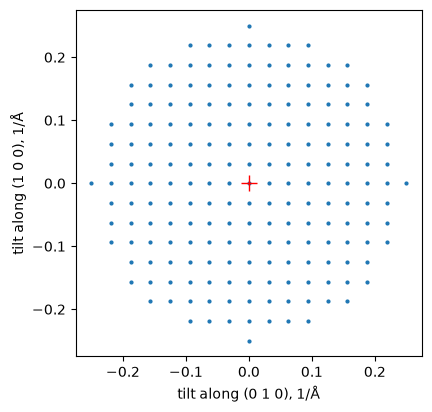

In [3]:
nib, details = silicon.getIBDetails(bPrint=False)

tilts = np.array([d['tilt'] for d in details]) / a          # 1/Å
lam = 1 / K
print(f"Point {tuple(int(i) for i in details[0]['ib'])}: tilt {np.linalg.norm(tilts[0]):.4f} 1/Å, "
      f'{np.linalg.norm(tilts[0]) * lam * 1e3:.2f} mrad')

fig, ax = plt.subplots(figsize=(4.5, 4.5))
ax.plot(tilts[:, 1], tilts[:, 0], '.', markersize=4)
ax.plot(0, 0, 'r+', markersize=12)
ax.set_xlabel('tilt along (0 1 0), 1/Å')
ax.set_ylabel('tilt along (1 0 0), 1/Å')
ax.set_aspect('equal')
plt.show()

The outermost points are tilted by 0.25 1/Å, the disk size, about 6 mrad at 200 kV. Each
point becomes a pixel region of every CBED disk.

## Step 3: The scattering matrix at one point

`getSCMatrix` returns, at one sampling point and thickness (200 Å by default), the matrix size
$N$, the scattering matrix $S$, the eigenvalues $\lambda_j$, and the beams:

In [4]:
ndim, S, eigenvalues, beams = silicon.getSCMatrix(ib_coords=(0, 0))

print(f'{ndim} beams; S is {S.shape[0]} × {S.shape[1]}, {S.dtype}')


def label(hkl):
    return '(' + ' '.join(str(int(i)) for i in hkl) + ')'


print()
print('  beam         intensity |S_g0|² at 200 Å')
for hkl, amplitude in zip(beams, S[:, 0]):
    print(f'  {label(hkl):12s} {abs(amplitude) ** 2:.4f}')

21 beams; S is 21 × 21, complex64

  beam         intensity |S_g0|² at 200 Å
  (0 0 0)      0.4722
  (0 -2 0)     0.0000
  (-2 0 0)     0.0000
  (2 0 0)      0.0000
  (0 2 0)      0.0000
  (2 -2 0)     0.0964
  (-2 2 0)     0.0962
  (-2 -2 0)    0.0961
  (2 2 0)      0.0958
  (0 -4 0)     0.0179
  (-4 0 0)     0.0178
  (4 0 0)      0.0178
  (0 4 0)      0.0178
  (2 -4 0)     0.0000
  (4 -2 0)     0.0000
  (-4 2 0)     0.0000
  (-2 4 0)     0.0000
  (-2 -4 0)    0.0000
  (-4 -2 0)    0.0000
  (4 2 0)      0.0000
  (2 4 0)      0.0000


At the zone axis, the direct beam keeps 47% of the electrons, and each (2 2 0)-type
reflection gets almost 10%. The (2 0 0)-type beams are forbidden in the diamond structure, and
stay at zero.

These numbers are the CBED pattern at this incident direction. `getBlochImages`, in the same
session, makes the images. The point (0, 0) is the center of the (0 0 0) disk, which pyEMAPS
puts at row 254, column 255 of the 512 × 512 image, next to the detector's center:

In [5]:
emc, image = silicon.getBlochImages(sample_thickness=(200, 200, 100))[0]
print(f'Image at row 254, column 255: {image[254, 255]:.4f}')
print(f'|S_00|²:                      {abs(S[0, 0]) ** 2:.4f}')

Image at row 254, column 255: 0.4722


|S_00|²:                      0.4722


## Step 4: Absorption

Without absorption, every electron would end up in some beam, and the intensities in each column
of $S$ would add up to 1: $S$ would be unitary. With absorption, they add up to less, and less
as the sample gets thicker:

In [6]:
print('  thickness   electrons left in the beams   largest |S†S - I|')
for t in (0, 200, 500, 1000, 2000, 3000):
    _, St, _, _ = silicon.getSCMatrix(ib_coords=(0, 0), sample_thickness=t)
    total = (abs(St[:, 0]) ** 2).sum()
    deviation = abs(St.conj().T @ St - np.eye(ndim)).max()
    print(f'  {t:5d} Å     {total:.3f}                         {deviation:.3f}')

  thickness   electrons left in the beams   largest |S†S - I|
      0 Å     1.000                         0.000
    200 Å     0.928                         0.072
    500 Å     0.844                         0.156
   1000 Å     0.734                         0.266
   2000 Å     0.532                         0.468
   3000 Å     0.381                         0.619


pyEMAPS leaves out the mean absorption, the part of $U'$ that dims every beam equally, and
keeps the part that depends on the beams. So these numbers show how unevenly electrons are
absorbed, not the full loss.

## Step 5: The Bloch waves

The eigenvalues are complex: their real parts set how fast each Bloch wave's phase advances
through the crystal, and their imaginary parts how fast it is absorbed. pyEMAPS returns them in
1/Å², as $\lambda_j = 2K\gamma_j$. First, check the convention: the eigenvalues of $S(t)$ should
be $e^{-2\pi i \lambda_j t / 2K}$.

In [7]:
t = 200
predicted = np.exp(-2j * np.pi * eigenvalues.astype(complex) * t / (2 * K))
actual = np.linalg.eigvals(S.astype(complex))
mismatch = max(abs(actual - p).min() for p in predicted)
print(f'Eigenvalues of S({t} Å) against exp(-2πiλt/2K): largest difference {mismatch:.1e}')

_, S100, _, _ = silicon.getSCMatrix(ib_coords=(0, 0), sample_thickness=100)
_, S300, _, _ = silicon.getSCMatrix(ib_coords=(0, 0), sample_thickness=300)
print(f'S(300) against S(200) S(100): largest difference {abs(S @ S100 - S300).max():.1e}')

Eigenvalues of S(200 Å) against exp(-2πiλt/2K): largest difference 5.2e-05
S(300) against S(200) S(100): largest difference 5.0e-07


Both hold, to the single precision of the matrices. Now, which Bloch waves matter? The
direct beam's amplitude is a sum over the Bloch waves,

$$S_{00}(t) = \sum_j C_{0j}\, (C^{-1})_{j0}\, e^{-2\pi i \lambda_j t / 2K}$$

and the weights $C_{0j} (C^{-1})_{j0}$ say how much each contributes. The eigenvectors of $S$ are
the Bloch waves, so `numpy.linalg.eig` gives $C$:

In [8]:
mu, C = np.linalg.eig(S.astype(complex))
weights = C[0, :] * np.linalg.inv(C)[:, 0]
# each eigenvalue of S belongs to one λ_j; match them
lam_of = [eigenvalues[np.argmin(abs(predicted - m))] for m in mu]

order = np.argsort(-abs(weights))
print('  Bloch wave λ (1/Å²)              weight in S_00')
for j in order[:4]:
    print(f'  {complex(lam_of[j]):.4f}          {abs(weights[j]):.3f}')

l1, l2 = lam_of[order[0]], lam_of[order[1]]
period = 2 * K / abs(l1.real - l2.real)
print(f'Two Bloch waves carry {abs(weights[order[0]]) + abs(weights[order[1]]):.1%} of the direct beam.')
print(f'Their beat period, 2K / |λ1 - λ2|: {period:.1f} Å')

  Bloch wave λ (1/Å²)              weight in S_00


  0.0468-0.0022j          0.825
  -0.2065-0.0015j          0.174
  -0.5359-0.0002j          0.002
  -0.3045+0.0006j          0.000
Two Bloch waves carry 99.8% of the direct beam.
Their beat period, 2K / |λ1 - λ2|: 314.8 Å


Two Bloch waves dominate. As they travel through the crystal, they drift in and out of
phase, and the direct beam's intensity swings with their beat period. Follow it through 3000 Å
of Silicon, one scattering matrix per 10 Å, and mark the predicted period:

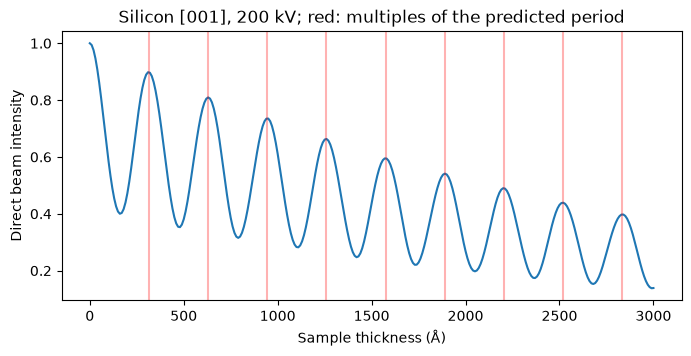

Maxima at [310, 630, 950, 1260, 1570, 1890, 2200, 2520, 2840] Å


In [9]:
thickness = np.arange(0, 3001, 10)
I0 = []
for t in thickness:
    _, St, _, _ = silicon.getSCMatrix(ib_coords=(0, 0), sample_thickness=int(t))
    I0.append(abs(St[0, 0]) ** 2)
I0 = np.array(I0)

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(thickness, I0)
for k in range(1, int(thickness[-1] / period) + 1):
    ax.axvline(k * period, color='red', alpha=0.3)
ax.set_xlabel('Sample thickness (Å)')
ax.set_ylabel('Direct beam intensity')
ax.set_title('Silicon [001], 200 kV; red: multiples of the predicted period')
plt.show()

maxima = [int(thickness[i]) for i in range(1, len(I0) - 1) if I0[i - 1] < I0[i] >= I0[i + 1]]
print('Maxima at', maxima, 'Å')

The maxima follow the predicted period. It's close to the ~316 Å the dynamic diffraction
notebook measured from the CBED images, with slightly different controls, and now traced to two
eigenvalues. The swings fade because the two
Bloch waves are absorbed at different rates: their eigenvalues' imaginary parts differ.

## Step 6: Other sampling points

At another incident direction, the excitation errors change, and with them the beams that pass
the limits of the calculation. The matrix size varies across the disk:

Matrix sizes: 21 to 27


Beams with images: 21, all within 1 1/Å: 0.823 1/Å at most


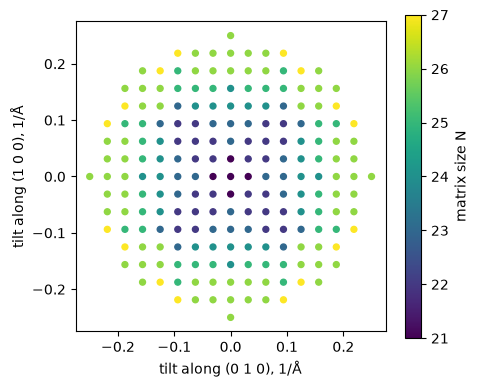

In [10]:
sizes = np.array([silicon.getSCMatrix(ib_coords=p)[0] for p in points])
print(f'Matrix sizes: {sizes.min()} to {sizes.max()}')

nbeams, calculated = silicon.getCalculatedBeams()
print(f'Beams with images: {nbeams}, all within 1 1/Å: '
      f'{max(np.linalg.norm(b) for b in calculated) / a:.3f} 1/Å at most')

fig, ax = plt.subplots(figsize=(5, 4.2))
sc = ax.scatter(tilts[:, 1], tilts[:, 0], c=sizes, s=18, cmap='viridis')
fig.colorbar(sc, label='matrix size N')
ax.set_xlabel('tilt along (0 1 0), 1/Å')
ax.set_ylabel('tilt along (1 0 0), 1/Å')
ax.set_aspect('equal')
plt.show()

silicon.endBloch()

Near the edge of the disk, the incident beam tilts towards some outer reflections, such as
(6 0 0), and they join the calculation. `getCalculatedBeams` lists the 21 beams that get images:
those inside the objective aperture, 1 1/Å by default. The others take part in the
calculation, but have no image. `endBloch` ends the session and frees its memory.

## Going further: inside the matrix

$S$ holds the whole calculation, so the matrix $A$ can be recovered from it:
$A = \frac{2K}{-2\pi i t} \log S(t)$. The logarithm needs $t$ small enough that no phase
$2\pi\lambda_j t/2K$ passes $\pi$; 10 Å is. With the eigenvectors of $S$:

In [11]:
U = {sf['hkl']: sf['amp_re'] for sf in silicon.generateCSF(kv=200, smax=1.5, sftype=3, aptype=1)[1:]}


def recover(controls, **options):
    silicon.beginBloch(em_controls=controls, dbsize=DISK_SIZE, **options)
    n, St, _, b = silicon.getSCMatrix(ib_coords=(0, 0), sample_thickness=10)
    silicon.endBloch()
    mu, C = np.linalg.eig(St.astype(complex))
    A = C @ np.diag(np.log(mu)) @ np.linalg.inv(C) * 2 * K / (-2j * np.pi * 10)
    return n, A, b


def show(n, A, b):
    print(f'{n} beams in the matrix')
    print('  beam g      A_gg      -|g|²      |A_0g|     |U_g|')
    rows = [tuple(int(i) for i in hkl) for hkl in b]
    for g in ((2, -2, 0), (0, -4, 0)):     # a (2 2 0)-type and a (4 0 0)-type beam
        k, g = rows.index(g), np.array(g)
        Ug = U[tuple(sorted(abs(int(i)) for i in g))]
        print(f'  {label(g):10s} {A[k, k].real:+.4f}   {-(g @ g) / a**2:+.4f}    '
              f'{abs(A[0, k]):.4f}    {Ug:.4f}')


show(*recover(EMC(cl=200, simc=SIMC(gmax=2.0, excitation=(1.0, 2.0)))))

21 beams in the matrix
  beam g      A_gg      -|g|²      |A_0g|     |U_g|
  (2 -2 0)   -0.2678   -0.2713    0.0420    0.0400
  (0 -4 0)   -0.5381   -0.5425    0.0259    0.0238


The diagonal is close to $2K s_{\mathbf g} = -|\mathbf g|^2$, the excitation error at the
exact zone axis. The couplings $|A_{0\mathbf g}|$ are close to $|U_{\mathbf g}|$, but 5 to 9%
larger. The difference is the beams left out. To keep the matrix small, pyEMAPS includes only
the strongly excited beams. The weak ones still matter, and it folds them into the matrix as
**Bethe potentials**:

$$A_{\mathbf g \mathbf h} = U_{\mathbf g - \mathbf h} - \sum_{\mathbf k\ \mathrm{weak}}
\frac{U_{\mathbf g - \mathbf k}\, U_{\mathbf k - \mathbf h}}{2K s_{\mathbf k}}$$

and the same on the diagonal. Two settings decide which beams count as strong: the
diagonalization cutoff `omega` of `beginBloch`, and the perturbation cutoff `bmin` of `SIMC`.
Raise one and lower the other, and many more beams go into the matrix:

In [12]:
show(*recover(EMC(cl=200, simc=SIMC(gmax=2.0, excitation=(1.0, 2.0), bmin=0.0)), omega=1000))

193 beams in the matrix
  beam g      A_gg      -|g|²      |A_0g|     |U_g|
  (2 -2 0)   -0.2709   -0.2713    0.0402    0.0400
  (0 -4 0)   -0.5420   -0.5425    0.0241    0.0238


With every beam in the matrix, there is almost nothing left to fold in: the couplings come
within 1.5% of $U_{\mathbf g}$, and the diagonal within 0.2% of $-|\mathbf g|^2$. The
matrix is about nine times larger, for intensities that change little: that's the trade-off the Bethe potentials make.

## The sample

*si_scm.py* has two functions. `print_scattering_matrices` prints everything above, at the
central point and at a random one: the matrices are 21 × 21, so it's long.
`all_scattering_matrices` returns the results at every sampling point:

In [13]:
from pyemaps.samples.si_scm import all_scattering_matrices

beams_info, matrices, incident = all_scattering_matrices()
print(beams_info['ncb'], 'calculated beams;', matrices['nscm'], 'sampling points;',
      incident['nib'], 'incident beam tilts')
first = matrices['lscm'][0]
print('First point:', first['ib'], 'with a', first['ndim'], '×', first['ndim'], 'matrix')

21

 calculated beams; 197 sampling points; 197 incident beam tilts
First point: (0, -8) with a 26 × 26 matrix


## Try it yourself

1. **Away from the zone axis.** Start a session with `tilt=(1.0, 0.0)` in the controls. How
   many Bloch waves carry the direct beam now, and what's the period of its intensity?
2. **High voltage.** Repeat Step 5 at 100 kV (`EMC(vt=100, ...)`). Does the period get longer
   or shorter, and by how much?
3. **Thickness.** At which thickness, in Step 5, is the direct beam at its weakest? Look at the
   (2 2 0)-type intensities there.
4. **Symmetry.** At the point (0, 0), the four (2 2 0)-type beams have the same intensity. Find a
   sampling point where they don't, and explain why.

## Next

- The [dynamic diffraction notebook](si_bloch.ipynb): CBED images from the same calculation.
- The [LACBED notebook](si_lacbed.ipynb): each beam's intensity over a large range of incident
  directions.
- The [structure factors notebook](si_csf.ipynb): the $U_{\mathbf g}$ and $U'_{\mathbf g}$ in
  the matrix.
- The references for [`beginBloch`](https://emlab-solutions.github.io/pyemaps/api/crystals.html#pyemaps.crystals.Crystal.beginBloch),
  [`getSCMatrix`](https://emlab-solutions.github.io/pyemaps/api/crystals.html#pyemaps.crystals.Crystal.getSCMatrix),
  [`getIBDetails`](https://emlab-solutions.github.io/pyemaps/api/crystals.html#pyemaps.crystals.Crystal.getIBDetails) and
  [`getCalculatedBeams`](https://emlab-solutions.github.io/pyemaps/api/crystals.html#pyemaps.crystals.Crystal.getCalculatedBeams).

## Further reading

J. C. H. Spence and J. M. Zuo, *Electron Microdiffraction* (Plenum, New York, 1992),
[doi:10.1007/978-1-4899-2353-0](https://doi.org/10.1007/978-1-4899-2353-0):

- chapter 3, *Theory*, for the equations and the Going further section;
- chapter 4, *The Measurement of Low-Order Structure Factors and Thickness*, for Step 5.

J. M. Zuo and J. C. H. Spence, *Advanced Transmission Electron Microscopy* (Springer, New York,
2017), [doi:10.1007/978-1-4939-6607-3](https://doi.org/10.1007/978-1-4939-6607-3):

- chapter 5, *Dynamical Theory of Electron Diffraction for Perfect Crystals*, for the equations
  and Steps 3 to 6.